# **Glioma Grading (LGGvsGBM): predicting tumour grade from clinical and mutational profile.**

**Francesca Crispino, 0001233884**

**Course:** Applied Machine Learning-Basic, A.Y. 2025/2026







## Theoretical overview and state of the art

**Gliomas** are the most common primary tumours of the central nervous system and arise from glial cells. Based on their biological aggressiveness they are divided into:

- **LGG (Lower-Grade Glioma)**: WHO grades II–III (astrocytomas, oligodendrogliomas, mixed gliomas), slower growth and better prognosis;
- **GBM (Glioblastoma Multiforme)**: WHO grade IV, the most aggressive primary brain tumour.
- **Grading** guides the therapeutic choice. Since 2016, and even more with the WHO CNS 2021 classification, glioma diagnosis is no longer based on histology alone but integrates molecular markers:

| Marker | Clinical meaning |
|---|---|
| **IDH1/IDH2** | mutated: typical of lower-grade gliomas (LGG); wildtype: typical of glioblastoma (GBM) |
| **ATRX**, **TP53** | astrocytic lineage (IDH-mutant astrocytoma) |
| **CIC**, **FUBP1** (together with the 1p/19q codeletion) | oligodendroglial lineage |
| **PTEN**, **EGFR**, **RB1** | alterations typical of glioblastoma |


- The chosen dataset was taken from the following paper:

> Tasci E., Zhuge Y., Kaur H., Camphausen K., Krauze A.V. (2022).
> *Hierarchical Voting-Based Feature Selection and Ensemble Learning Model Scheme for Glioma Grading with Clinical and Molecular Characteristics.*
> **International Journal of Molecular Sciences**, 23(22), 14155. doi:[10.3390/ijms232214155](https://doi.org/10.3390/ijms232214155)

 The WHO classification uses IDH status as a diagnostic criterion. The IDH1 gene encodes an enzyme that converts isocitrate into α-ketoglutarate, producing NADPH, which protects the cell from oxidative stress. IDH-mutant gliomas, in which the gene carries a mutation that alters the enzyme function, are typically lower-grade (LGG), while IDH-wildtype gliomas, which carry the normal version of the gene, are typically glioblastomas (GBM).



## Machine learning framing

The project addresses a **supervised binary classification problem on tabular data**: predicting the tumour grade from clinical and mutational features.

**Binary classification**, target = **Grade**(LGG = 0, GBM = 1)
   > *Can tumour grade (LGG vs GBM) be predicted from the patient's clinical and mutational profile, and in particular from IDH1 status?*

   **Expected outcome:** the model reconstructs this clinical distinction, and IDH1 is expected to emerge as the most predictive feature.

The reference study for this project, addressed the same problem of glioma grading (LGG vs GBM) from clinical and molecular features, on the same TCGA dataset. Their method combines a *voting-based feature selection* with a *soft-voting ensemble* of classical classifiers (LR, SVM, KNN, Random Forest, AdaBoost), evaluated with 10-fold
cross-validation.
However, this project focuses only on the standard machine learning methods covered in the course.

**What the paper does not address** (and this project adds):
- the **isolated contribution of IDH1** compared with all the other features.
- an **error analysis** relating the misclassified patients to IDH1 status and the WHO 2021 classification.

**What this project takes from the paper:** the dataset (862 patients) and the evaluation protocol (10-fold CV, random_state = 0,
z-score on age, GBM as positive class).

## Dataset

**Source:**
The *Glioma Grading Clinical and Mutation Features* dataset was retrieved from the UCI Machine Learning Repository (CC BY 4.0 licence).
The file used is `TCGA_GBM_LGG_Mutations_all.csv`, which collects both clinical and mutational data from the **TCGA-LGG** and **TCGA-GBM** projects (The Cancer Genome Atlas, NCI Genomic Data Commons).

## Workflow

0. Libraries
1. Load Dataset
2. Data Cleaning
3. Exploratory Data Analysis
4. Preprocessing
5. Feature Selection
6. Resampling
7. Models
8. Final Model
9. Error Analysis
10. Feature subsets comparison
11. Hyperparameters tuning
12. Conclusions and Limitations (12.1)


## Libraries

In [1]:
#Data handling
import re
import numpy as np
import pandas as pd

#Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

#Feature selection
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import RFE
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier

#Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

#Resampling and model evaluation
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix

#Metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import recall_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score, precision_score

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

#Project palette (derived from ColorBrewer 'BrBG')
BROWN_D, BROWN, BROWN_L = '#8c510a', '#bf812d', '#dfc27d'
TEAL_L,  TEAL,  TEAL_D  = '#80cdc1', '#35978f', '#01665e'
SOFT_GREY = '#d9d3c7'
BLACK = '#0b0b0b'

#Semantic colours: same class = same colour in every plot
LGG_COLOR, GBM_COLOR = BROWN, TEAL
GRADE_PALETTE = {'LGG': LGG_COLOR, 'GBM': GBM_COLOR}

#Colormap:
CMAP = sns.blend_palette([BROWN_D, BROWN, BROWN_L, SOFT_GREY, TEAL_L, TEAL, TEAL_D], as_cmap=True)
#Sequential colormap (percentages, counts)
CMAP_SEQ = sns.blend_palette(['#f3f1ec', TEAL_L, TEAL, TEAL_D], as_cmap=True)

#Plots theme:
sns.set_theme(style='whitegrid')



# 1. Load Dataset

In [2]:
#The dataset is available in my personal GitHub repository, so it is loaded directly from its URL for better reproducibility.
url = 'https://raw.githubusercontent.com/Francesca-Crispino/ML_Basic_Project/refs/heads/main/TCGA_GBM_LGG_Mutations_all.csv'

#Creating a pandas DataFrame with raw data
df = pd.read_csv(url, encoding='utf-8-sig') # 'utf-8-sig' to remove the initial file BOM.
print(df.shape)
df.head(10)

(862, 27)


,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,LGG,TCGA-LGG,TCGA-DU-8164,Male,51 years 108 days,"Oligodendroglioma, NOS",white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
1,LGG,TCGA-LGG,TCGA-QH-A6CY,Male,38 years 261 days,Mixed glioma,white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
2,LGG,TCGA-LGG,TCGA-HW-A5KM,Male,35 years 62 days,"Astrocytoma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
3,LGG,TCGA-LGG,TCGA-E1-A7YE,Female,32 years 283 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,MUTATED,NOT_MUTATED
4,LGG,TCGA-LGG,TCGA-S9-A6WG,Male,31 years 187 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
5,LGG,TCGA-LGG,TCGA-DB-A4X9,Female,33 years 78 days,Mixed glioma,white,MUTATED,NOT_MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
6,LGG,TCGA-LGG,TCGA-P5-A5F4,Female,35 years 68 days,"Oligodendroglioma, anaplastic",white,MUTATED,MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
7,LGG,TCGA-LGG,TCGA-FG-A4MY,Female,44 years 239 days,Mixed glioma,white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
8,LGG,TCGA-LGG,TCGA-HT-A5R5,Female,33 years 350 days,"Oligodendroglioma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
9,LGG,TCGA-LGG,TCGA-DU-A76K,Male,87 years,"Oligodendroglioma, NOS",white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED


In [3]:
#Initial inspection of the dataset structure:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Grade              862 non-null    object
 1   Project            862 non-null    object
 2   Case_ID            862 non-null    object
 3   Gender             862 non-null    object
 4   Age_at_diagnosis   862 non-null    object
 5   Primary_Diagnosis  862 non-null    object
 6   Race               862 non-null    object
 7   IDH1               862 non-null    object
 8   TP53               862 non-null    object
 9   ATRX               862 non-null    object
 10  PTEN               862 non-null    object
 11  EGFR               862 non-null    object
 12  CIC                862 non-null    object
 13  MUC16              862 non-null    object
 14  PIK3CA             862 non-null    object
 15  NF1                862 non-null    object
 16  PIK3R1             862 non-null    object
 1

Initial inspection shows that the dataset has 862 rows (one per patient) and 27 columns: 'grade', 'project', patient identifier, three clinical variables ('Gender', 'Age_at_diagnosis', 'Race'), the histological diagnosis ('Primary_Diagnosis') and 20 gene columns.

In [4]:
#Summary statistics:
df.describe()

,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,862,862,862,862,862,862,862,862,862,862,...,862,862,862,862,862,862,862,862,862,862
unique,2,2,862,3,838,7,6,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,LGG,TCGA-LGG,TCGA-DU-8164,Male,--,Glioblastoma,white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
freq,499,499,1,499,5,360,766,448,508,642,...,815,821,824,833,834,834,835,839,839,840


**Comments:**
Since all columns are stored as text (object), the function *describe()* returns categorical statistics instead of means and standard deviations.

Some observations:
- Case_ID has 862 unique values out of 862 rows: each patient appears only once.
- Grade has 2 classes, with LGG as the most frequent (499 patients).
- Gender has 3 unique values instead of 2, and Race has 6, both contain placeholders for missing data.
- The most frequent value of Age_at_diagnosis is '--'(5 patients), in this case, missing values are encoded as text, so they are not detected as NaN, therefore they need to be inspected in the following cell with the *value_counts()*.
- Primary_Diagnosis has 7 unique values: 6 histological diagnoses plus the '--' placeholder.
- The 20 genes have 2 values each (MUTATED / NOT_MUTATED), with NOT_MUTATED as the most frequent.



In [5]:
#Value counts for category variables: Gender, Race and Primary_Diagnosis (looking for placeholders)
for col in ['Gender', 'Race', 'Primary_Diagnosis']:
  print(df[col].value_counts(), '\n')

Gender
Male      499
Female    359
--          4
Name: count, dtype: int64 

Race
white                               766
black or african american            59
not reported                         18
asian                                14
--                                    4
american indian or alaska native      1
Name: count, dtype: int64 

Primary_Diagnosis
Glioblastoma                     360
Astrocytoma, anaplastic          129
Mixed glioma                     128
Oligodendroglioma, NOS           108
Oligodendroglioma, anaplastic     75
Astrocytoma, NOS                  58
--                                 4
Name: count, dtype: int64 



The value counts for each category show that missing values encoded as text appear in all three columns (4 patients each) and Race also contains 'not reported' (18 patients). These values must be converted into real missing values (NaN) during the data cleaning step, otherwise pandas treats them as valid categories.

# 2. Data Cleaning
Data Cleaning is the step in which the raw data are checked and corrected before any analysis, because the quality of the results is directly linked with the quality of the data.
Typical operations are:
- Checking and removing Duplicates
- Handling Missing values: they can be removed or imputed with a  consistent value (e.g. mean, median, most frequent category). Removal avoids inventing information, but it reduces the sample size; imputation preserves the data but introduces assumptions.
- Type conversion: variables stored as text but containing numbers or dates are converted so that models can use them.

In this project, the cleaning consists of checking for duplicates, converting the text placeholders into real missing values, removing the patients with missing data and converting Age_at_diagnosis into a numeric variable.   

In [6]:
#Check the duplicates
print(f"Duplicates: {df.duplicated().sum()}")

#Replace the text placeholders ("--", "Not reported") with real NaN.
df.replace(['--', 'not reported'], np.nan, inplace=True)

#Check the missing values
missing = df.isnull().sum()
print("\nMissing values:")
print(missing[missing > 0])

#Drop rows with missing values
shape_before = df.shape
df = df.dropna().reset_index(drop=True)
print("\nShape before drop:", shape_before)
print("Shape after drop:", df.shape)

Duplicates: 0

Missing values:
Gender                4
Age_at_diagnosis      5
Primary_Diagnosis     4
Race                 22
dtype: int64

Shape before drop: (862, 27)
Shape after drop: (839, 27)


In [7]:
#Type conversion and creation of a new DataFrame:
#Age_at_diagnosis is stored as text (e.g. "51 years 108 days"), so it cannot be used directly by the models.
gene_cols = ['IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1',
             'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4',
             'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']

def parse_age(age_str):
    """The function parse_age extracts the number of years and days with regular expressions and converts them into a single decimal value: years + days / 365."""
    if pd.isna(age_str):
        return np.nan
    years = re.search(r'(\d+)\s*years', age_str)
    days = re.search(r'(\d+)\s*days', age_str)
    years = int(years.group(1)) if years else 0
    days = int(days.group(1)) if days else 0
    return round(years + days / 365, 2)

#Applying the function for the conversion of the Age_at_diagnosis column
df['Age_at_diagnosis'] = df['Age_at_diagnosis'].apply(parse_age)

#Creating a new pandas dataframe to store categorical columns and gene_cols after with the cleaned data.
categorical_cols = ['Grade', 'Project', 'Gender', 'Race', 'Primary_Diagnosis']
df[categorical_cols + gene_cols] = df[categorical_cols + gene_cols].astype('category')

df.head(10)


,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,LGG,TCGA-LGG,TCGA-DU-8164,Male,51.30,"Oligodendroglioma, NOS",white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
1,LGG,TCGA-LGG,TCGA-QH-A6CY,Male,38.72,Mixed glioma,white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
2,LGG,TCGA-LGG,TCGA-HW-A5KM,Male,35.17,"Astrocytoma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
3,LGG,TCGA-LGG,TCGA-E1-A7YE,Female,32.78,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,MUTATED,NOT_MUTATED
4,LGG,TCGA-LGG,TCGA-S9-A6WG,Male,31.51,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
5,LGG,TCGA-LGG,TCGA-DB-A4X9,Female,33.21,Mixed glioma,white,MUTATED,NOT_MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
6,LGG,TCGA-LGG,TCGA-P5-A5F4,Female,35.19,"Oligodendroglioma, anaplastic",white,MUTATED,MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
7,LGG,TCGA-LGG,TCGA-FG-A4MY,Female,44.65,Mixed glioma,white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
8,LGG,TCGA-LGG,TCGA-HT-A5R5,Female,33.96,"Oligodendroglioma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
9,LGG,TCGA-LGG,TCGA-DU-A76K,Male,87.00,"Oligodendroglioma, NOS",white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED


# 3. Exploratory Data Analysis
Exploratory Data Analysis (EDA) is the step in which the cleaned data are examined mainly with summary statistics and plots, to understand their distribution and the relationships between variables, and to guide the preprocessing and modelling choices.
In this project, the EDA examines the class distribution (LGG vs GBM), the correlation of each feature with the grade, the frequency of the gene mutations overall, by grade and by histological subtype, and the distribution of age, gender and race.

In [8]:
#Class distribution
print(df['Grade'].value_counts(), '\n')
print(df['Primary_Diagnosis'].value_counts(), '\n')

print("\nProject vs Grade:")
print(pd.crosstab(df['Project'], df['Grade']))

print("\nPrimary_Diagnosis vs Grade:")
print(pd.crosstab(df['Primary_Diagnosis'], df['Grade']))

Grade
LGG    487
GBM    352
Name: count, dtype: int64 

Primary_Diagnosis
Glioblastoma                     352
Astrocytoma, anaplastic          127
Mixed glioma                     127
Oligodendroglioma, NOS           104
Oligodendroglioma, anaplastic     73
Astrocytoma, NOS                  56
Name: count, dtype: int64 


Project vs Grade:
Grade     GBM  LGG
Project           
TCGA-GBM  352    0
TCGA-LGG    0  487

Primary_Diagnosis vs Grade:
Grade                          GBM  LGG
Primary_Diagnosis                      
Astrocytoma, NOS                 0   56
Astrocytoma, anaplastic          0  127
Glioblastoma                   352    0
Mixed glioma                     0  127
Oligodendroglioma, NOS           0  104
Oligodendroglioma, anaplastic    0   73


- The binary task is only mildly imbalanced (487 LGG vs 352 GBM). Therefore, no rebalancing is applied; instead, stratified folds are used in the resampling step, which is sufficient to preserve the class proportions.

- **Project** coincides exactly with **Grade**, and **Glioblastoma** always corresponds to GBM. Both columns must be excluded from the features of the binary task in order to avoid data leakage.

In [9]:
#Numerical encoding and correlations
#Creation of a 'df_num' DataFrame which is the numerically encoded copy of 'df' (GBM=1, MUTATED=1, Female=1)
df_num = df.copy()
df_num['Grade']  = df_num['Grade'].map({'LGG': 0, 'GBM': 1}).astype(int)
df_num['Gender'] = df_num['Gender'].map({'Male': 0, 'Female': 1}).astype(int)
df_num[gene_cols] = (df_num[gene_cols] == 'MUTATED').astype(int)

#Pearson correlation matrix between the target, the clinical features and the 20 genes
corr_matrix = df_num[['Grade', 'Gender', 'Age_at_diagnosis'] + gene_cols].corr(method='pearson')

#Correlation of each feature with Grade (GBM = 1), sorted from the most positive (GBM) to the most negative (LGG)
print("PEARSON CORRELATION WITH GRADE")
print(corr_matrix['Grade'].drop('Grade').sort_values(ascending=False).round(3).to_frame())

#Skewness of age, the only continuous variable
print("\nSkew Age_at_diagnosis:", round(df_num['Age_at_diagnosis'].skew(), 3))

PEARSON CORRELATION WITH GRADE
                  Grade
Age_at_diagnosis  0.529
PTEN              0.367
EGFR              0.242
RB1               0.195
MUC16             0.119
GRIN2A            0.119
PDGFRA            0.102
PIK3R1            0.102
NF1               0.088
CSMD3             0.050
FAT4              0.035
PIK3CA            0.029
BCOR             -0.002
Gender           -0.060
SMARCA4          -0.100
IDH2             -0.113
TP53             -0.162
FUBP1            -0.181
NOTCH1           -0.185
CIC              -0.303
ATRX             -0.315
IDH1             -0.708

Skew Age_at_diagnosis: 0.074


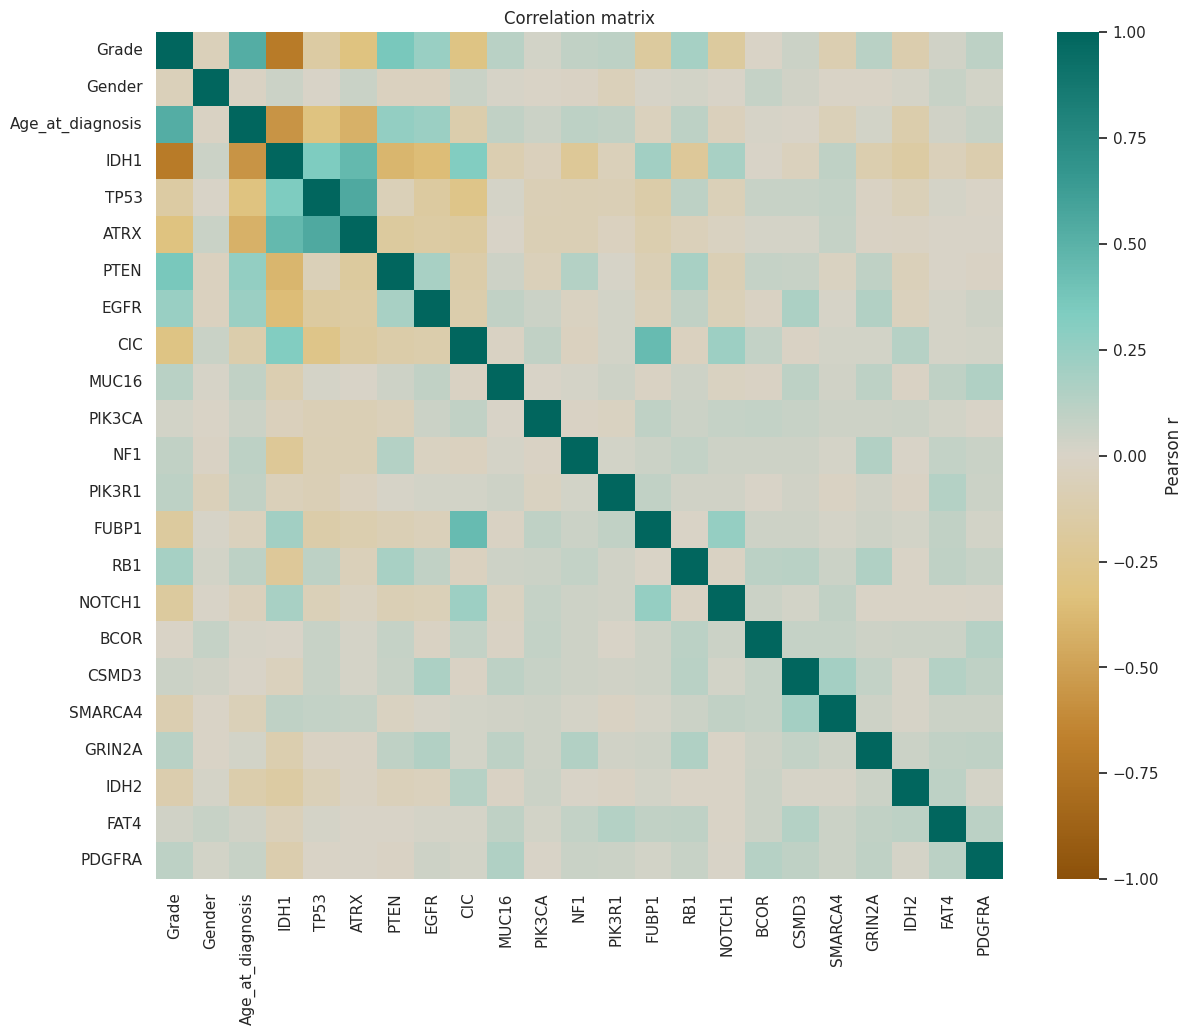

In [10]:
#Correlation matrix plot:
plt.figure(figsize=(14, 11))

sns.heatmap(corr_matrix,
            cmap=CMAP,
            center=0,
            vmin=-1,
            vmax=1,
            square=True,
            cbar_kws={'label': 'Pearson r'}
            )

plt.title('Correlation matrix')
plt.show()

**Comments:**
- The Pearson correlation was computed between all variables. The list reports the correlation of each feature with Grade (LGG = 0, GBM = 1), while the heatmap shows all pairwise correlations: brown cells indicate negative correlations, teal cells positive ones. The diagonal is always 1 (each variable with itself) and is not informative.

- *Correlation with grade:* IDH1 is by far the most associated feature (r = −0.71): IDH1 mutations are typical of LGG. It is followed by age (r = +0.53).
PTEN (+0.37), EGFR (+0.24) and RB1 (+0.20) are associated with GBM;
ATRX (−0.32), CIC (−0.30), NOTCH1 (−0.19) and FUBP1 (−0.18) with LGG.
The remaining genes and Gender (−0.06) show weak or negligible correlations and carry little individual information about the grade.

- *Correlation between features:*
The strongest colours are concentrated in the **top-left corner** of the heatmap, where the grade, age and the most frequently mutated genes are placed. Rare genes show only weak correlations.
IDH1 and age are moderately negatively correlated: IDH1-mutant patients tend to be younger.
The heatmap shows the expected co-occurrence blocks: TP53–ATRX (astrocytic lineage) and CIC–FUBP1 (oligodendroglial lineage). Both blocks are positively correlated with IDH1 and negatively correlated with each other, while PTEN and EGFR are negatively correlated with IDH1.

- Age has a *skewness of 0.07* (almost symmetric distribution), so standardisation is enough and no transformation is needed.

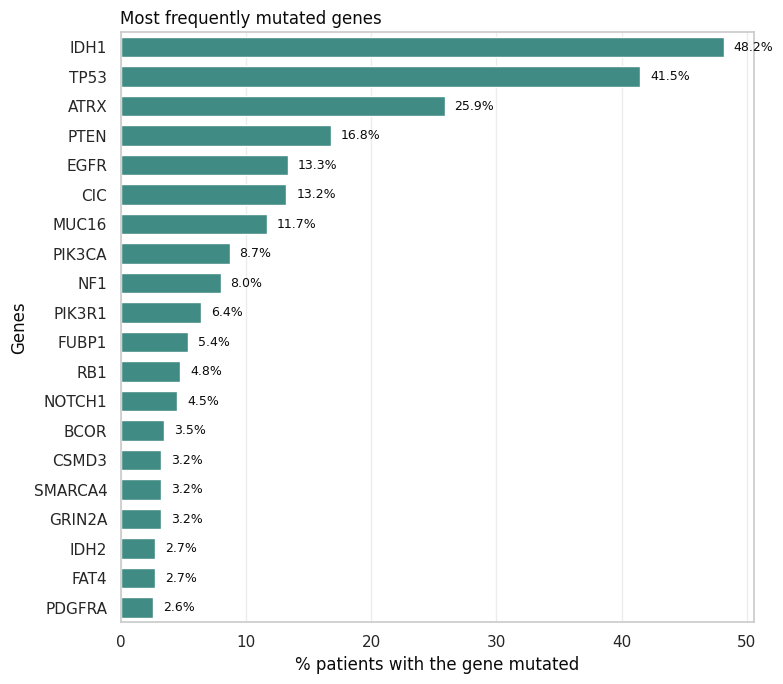

In [11]:
#Most frequently mutated genes: the plot below shows the % of mutated cases per gene, computed over the 20 genes and the 839 patients.

# % mutated over the whole dataset
percentage = (df_num[gene_cols].mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(x=percentage.values,
            y=percentage.index,
            color=TEAL,
            width=0.7,
            ax=ax
            )
#Setting the % label next to each bar
for y, v in enumerate(percentage.values):
    ax.text(v + 0.8, y, f'{v:.1f}%', va='center', fontsize=9, color=BLACK)

ax.set_xlabel('% patients with the gene mutated', color=BLACK)
ax.set_title('Most frequently mutated genes', loc='left', color=BLACK)
ax.set_ylabel('Genes', color=BLACK)
ax.xaxis.grid(True, color='#ececea')
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Comments:**
The bar plot shows the percentage of patients carrying each mutation, computed over all 839 patients regardless of grade. IDH1 is the most frequent mutation (48% of patients), followed by TP53 (42%) and ATRX (26%); the last two are typical markers of the astrocytic lineage. PTEN, EGFR and CIC are mutated in 13–17% of patients. The frequency then decreases gradually, and nine genes (RB1, NOTCH1, BCOR, CSMD3, SMARCA4, GRIN2A, FAT4, IDH2, PDGFRA) are mutated in fewer than 5% of patients, so the dataset is sparse and these rare genes can carry only limited information at the population level.
This plot shows how common a mutation is, not how well it distinguishes the two grades: this is shown by the table below.

In [12]:
#Mutational rate by grade
mut_rate = df_num.groupby('Grade')[gene_cols].mean().T * 100
mut_rate.columns = ['LGG', 'GBM']                       # Grade: 0 = LGG, 1 = GBM
mut_rate = mut_rate.loc[percentage.index]

print(mut_rate.round(1))

          LGG   GBM
IDH1     78.2   6.5
TP53     48.3  32.1
ATRX     37.6   9.7
PTEN      5.1  33.0
EGFR      6.4  23.0
CIC      22.0   1.1
MUC16     8.4  16.2
PIK3CA    8.0   9.7
NF1       6.0  10.8
PIK3R1    4.3   9.4
FUBP1     8.8   0.6
RB1       1.2   9.7
NOTCH1    7.8   0.0
BCOR      3.5   3.4
CSMD3     2.5   4.3
SMARCA4   4.7   1.1
GRIN2A    1.4   5.7
IDH2      4.3   0.6
FAT4      2.3   3.4
PDGFRA    1.2   4.5


**Comments:**
The table splits the mutation frequency by grade (genes are coded 0/1, so the mean within each group is the fraction of mutated patients). The genes with the largest gap between the two grades are the most informative.

IDH1 shows by far the largest difference (78.2% in LGG vs 6.5% in GBM), followed by ATRX (37.6% vs 9.7%) and PTEN (5.1% vs 33.0%), then by CIC (22.0% vs 1.1%). ATRX and CIC are typical of LGG, while PTEN is enriched in GBM, as are EGFR (6.4% vs 23.0%) and RB1 (1.2% vs 9.7%). FUBP1 and NOTCH1 are almost absent in GBM (0.6% and 0.0%), but they are mutated in less than 9% of LGG, so they are informative only for a few patients.

A frequent gene is not necessarily discriminant: TP53 is the second most frequent mutation overall, but it separates the grades only moderately (48.3% vs 32.1%, correlation −0.16), while EGFR, much rarer, has a similar absolute difference (6.4% vs 23.0%) but a much stronger association with GBM (correlation +0.24).

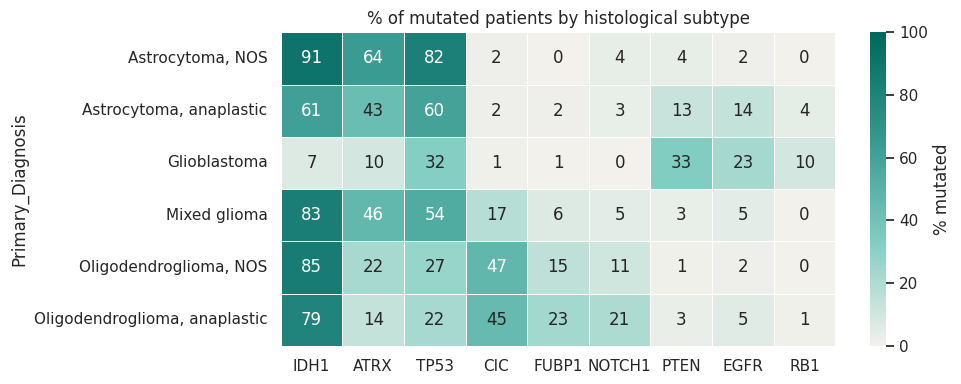

In [13]:
#Mutational profile by histological subtype
key_genes = ['IDH1', 'ATRX', 'TP53', 'CIC', 'FUBP1', 'NOTCH1', 'PTEN', 'EGFR', 'RB1']
subtype_profile = df_num.groupby('Primary_Diagnosis', observed=True)[key_genes].mean() * 100

plt.figure(figsize=(10, 4))
sns.heatmap(subtype_profile, annot=True, fmt='.0f', cmap=CMAP_SEQ, vmin=0, vmax=100, linewidths=0.5, linecolor='white', cbar_kws={'label': '% mutated'})
plt.title('% of mutated patients by histological subtype')
plt.tight_layout()
plt.show()

**Comments:**
The heatmap reproduces the molecular classification of gliomas across the histological subtypes.
IDH1 is mutated in most LGG subtypes (61–91%) and almost absent in Glioblastoma (7%).
ATRX and TP53 are frequent in astrocytomas (astrocytic lineage), while CIC is frequent and FUBP1 is enriched in oligodendrogliomas (oligodendroglial lineage).
Mixed glioma carries both astrocytic markers (ATRX 46%, TP53 54%) and some oligodendroglial ones (CIC 17%).
PTEN, EGFR and RB1 are mainly found in Glioblastoma.
The oligodendroglioma NOS and anaplastic variants have very similar profiles, so they differ mainly in histological grade rather than in mutations.
In astrocytomas, instead, the anaplastic variant has less IDH1 (61% vs 91%) and more PTEN and EGFR (13% and 14% vs 4% and 2%) than the NOS variant.

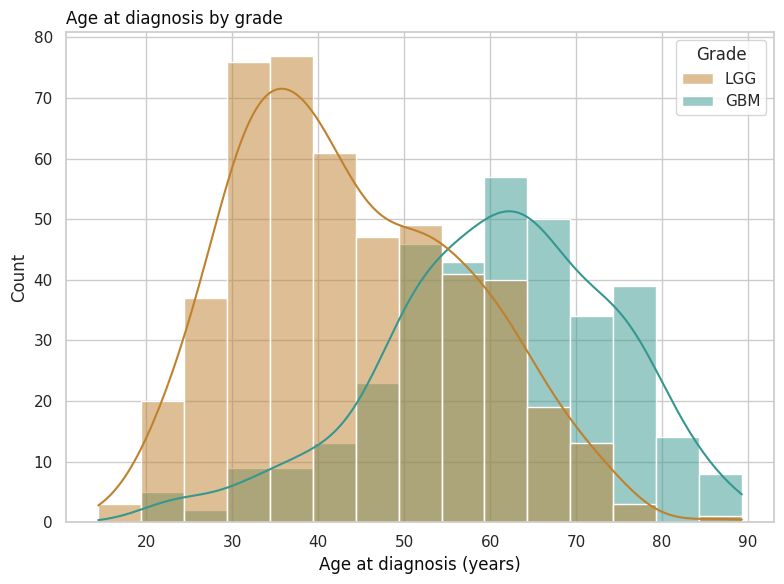

In [14]:
#Age at diagnosis by grade
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(data=df, x='Age_at_diagnosis', hue='Grade', hue_order=['LGG', 'GBM'], palette=GRADE_PALETTE, kde=True, ax=ax)
ax.set_title('Age at diagnosis by grade', loc='left', color=BLACK)
ax.set_xlabel('Age at diagnosis (years)', color=BLACK)
plt.tight_layout()
plt.show()

**Comments:** The two distributions are clearly shifted: LGG patients are mostly between 20 and 50 years of age, while GBM patients are older, with most cases after 50.

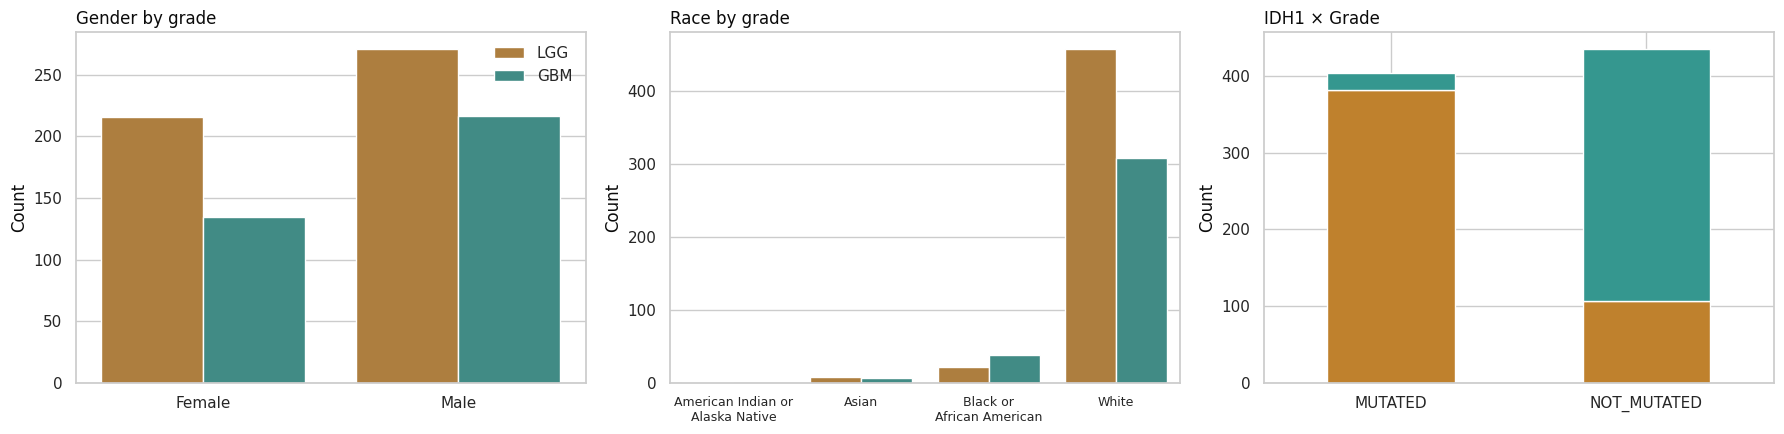


 Grade        GBM  LGG  All
IDH1                      
MUTATED       23  381  404
NOT_MUTATED  329  106  435
All          352  487  839

 Grade                             GBM  LGG  All
Race                                           
american indian or alaska native    0    1    1
asian                               6    8   14
black or african american          38   21   59
white                             308  457  765
All                               352  487  839


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

#Gender by grade (this plot keeps the legend for the whole figure)
sns.countplot(data=df, x='Gender', hue='Grade', hue_order=['LGG', 'GBM'], palette=GRADE_PALETTE, ax=ax[0])
ax[0].set_title('Gender by grade', loc='left', color=BLACK)
ax[0].set_xlabel('')
ax[0].set_ylabel('Count', color=BLACK)
ax[0].legend(title=None, frameon=False)

#Race by grade
sns.countplot(data=df, x='Race', hue='Grade', hue_order=['LGG', 'GBM'], palette=GRADE_PALETTE, legend=False, ax=ax[1])
#Setting shorter labels
short = {'white': 'White',
         'black or african american': 'Black or\nAfrican American',
         'asian': 'Asian',
         'american indian or alaska native': 'American Indian or\nAlaska Native'}
ax[1].set_xticks(ax[1].get_xticks())
ax[1].set_xticklabels([short[t.get_text()] for t in ax[1].get_xticklabels()], fontsize=9)
ax[1].set_title('Race by grade', loc='left', color=BLACK)
ax[1].set_xlabel('')
ax[1].set_ylabel('Count', color=BLACK)

#IDH1 status by grade
idh_grade = pd.crosstab(df['IDH1'], df['Grade'])[['LGG', 'GBM']]
idh_grade.plot(kind='bar', stacked=True, color=[LGG_COLOR, GBM_COLOR], rot=0, legend=False, ax=ax[2])
ax[2].set_title('IDH1 × Grade', loc='left', color=BLACK)
ax[2].set_xlabel('')
ax[2].set_ylabel('Count', color=BLACK)

plt.tight_layout()
plt.show()

print("\n", pd.crosstab(df['IDH1'], df['Grade'], margins = True))
print("\n", pd.crosstab(df['Race'], df['Grade'], margins = True))

**Comments:**
- Males are more numerous than females in both grades. The share of LGG is slightly higher among females (about 62% vs 55%), but the difference is small, in line with the weak correlation with grade (r = −0.06).
- The cohort is strongly dominated by white patients (765 of 839); the other groups are very small, and American Indian or Alaska Native has a single patient. Black or African American patients are GBM more often than white patients (38 of 59, 64%, vs 308 of 765, 40%).
- IDH1 status almost separates the two grades on its own: of the 404 IDH1-mutant patients, 381 are LGG, while of the 435 IDH1-wildtype patients, 329 are GBM.

**EDA summary:**

- IDH1 is the key feature: it is the most correlated with grade and its status already separates most patients: 381 of the 404 IDH1-mutant tumours are LGG, and 329 of the 435 IDH1-wildtype tumours are GBM.

- Age is the second most informative feature: GBM patients are older.

- Other genes add information in smaller amounts: PTEN, EGFR and RB1 are associated with GBM; ATRX, CIC, FUBP1 and NOTCH1 with LGG. Many genes are mutated in fewer than 5% of patients and carry little individual information.

- Gender is weakly related to grade. Race shows a difference between white and Black patients (64% vs 40% GBM), but it is heavily imbalanced and the smaller groups are too small for conclusions; it is therefore expected to add little to the model.

- The mutational profiles follow the known molecular lineages (astrocytic: IDH1 + TP53 + ATRX; oligodendroglial: IDH1 + CIC + FUBP1; glioblastoma: IDH1-wildtype, enriched in PTEN and EGFR), consistent with the WHO diagnostic criteria.

- The binary target is only mildly imbalanced (58% LGG / 42% GBM), and Project and Primary_Diagnosis must be excluded from the features to avoid data leakage.

Overall, the EDA suggests that a simple model should reach good performance, mainly driven by IDH1.

# 4. Preprocessing
Preprocessing transforms the data into the format required by machine learning models, which only accept numeric inputs and are sensitive to the scale of the variables, therefore the main operations are:

- Separating features and target: the matrix X (inputs) is separated from the vector y (the variable to predict), excluding identifiers and variables that would cause data leakage.
- Feature encoding: categorical variables are converted into numbers. Binary variables are coded 0/1, while categorical variables with more than two unordered categories are converted with one-hot encoding (one 0/1 column per category).
- Feature scaling: continuous variables are brought to a comparable scale (e.g. standardisation), so that variables with larger values do not dominate distance-based or regularised models.

To avoid data leakage, these transformations must be learned on the training data only; for this reason, they are combined in a pipeline that is fitted inside each cross-validation fold.

The 20 genes and Gender are already binary, Race is one-hot encoded and Age_at_diagnosis is standardised.

'Grade', the 20 genes and 'Gender' were already encoded as 0/1 in the EDA section (df_num).
'Race' need to be one-hot encoded.
'Age_at_diagnosis' need to be standardised.
'Race' needs one-hot encoding.


### Defining features (X) and target (y)

In supervised learning the data are split into two parts:
- **X – feature matrix** (patients × features): the information the model uses to decide.
  Each row is a patient, each column a feature.
- **y – target vector**: the answer the model has to learn to predict, one value per patient.

Features are grouped by type, because each type needs a different preprocessing step:

| Group | Feature | Type | Processing |
|---|---|---|---|
| `clinical_num` | Age_at_diagnosis | continuous | standardisation (z-score) |
| `clinical_bin` | Gender | binary 0/1 | none |
| `clinical_cat` | Race | categorical (4 values) | one-hot encoding |
| `gene_cols` | 20 genes | binary 0/1 | none |

**Columns excluded from X:** 'Case_ID' (identifier), 'Project' (coincides with Grade),
'Grade' (the target itself) , and 'Primary_Diagnosis' which both determine the grade exactly and would cause data leakage.

**Target:**
- `y_bin`: grade LGG (0) vs GBM (1)

In [16]:
#Defining the feature groups by type
clinical_num = ['Age_at_diagnosis']
clinical_bin = ['Gender']
clinical_cat = ['Race']

feature_cols = clinical_num + clinical_bin + clinical_cat + gene_cols #1 + 1 + 1 + 20 = 23 features

#Feature matrix X = rows = patients, columns = features : (839,23)
X = df_num[feature_cols].copy()
X['Race'] = X['Race'].astype(str) #from cat to str, for OneHotEncoder
Race_cat = sorted(X['Race'].unique())

#Binary target
y_bin = df_num['Grade']

#Check shape and class distribution
print("X:", X.shape)
print(y_bin.value_counts())
#print(X.head(10))

X: (839, 23)
Grade
0    487
1    352
Name: count, dtype: int64


### Step-by-step preprocessing

Features have different types, so each one gets a different transformation. We first look at each transformation
separately, then combine them into a single preprocessor.

#### Standardising age
Age ranges from 14 to 89 years, while all other features are 0/1. Without scaling, age would dominate
distance-based models (SVM, KNN) and regularised models such as Logistic Regression. The **z-score** maps each value to *(x − mean) / standard deviation*:
the result has mean 0 and standard deviation 1.

In [17]:
age_scaler = StandardScaler()
age_scaled = age_scaler.fit_transform(X[clinical_num])

print(f"Original age:     mean = {X['Age_at_diagnosis'].mean():6.2f}   std = {X['Age_at_diagnosis'].std():5.2f}")
print(f"Standardised age: mean = {age_scaled.mean():6.2f}   std = {age_scaled.std():5.2f}")

Original age:     mean =  50.94   std = 15.70
Standardised age: mean =   0.00   std =  1.00


#### One-hot encoding of Race
Since models only work with numbers,
**One-hot encoding** creates a 0/1 column for each category.


In [18]:
race_encoder = OneHotEncoder(categories=[Race_cat], sparse_output = False)
race_encoded = race_encoder.fit_transform(X[clinical_cat])
race_df = pd.DataFrame(race_encoded, columns=race_encoder.get_feature_names_out(), index=X.index)

print("Race categories:", Race_cat)
print("Created columns:", list(race_df.columns))
print(pd.concat([X['Race'], race_df], axis=1).drop_duplicates().to_string(index = False))

Race categories: ['american indian or alaska native', 'asian', 'black or african american', 'white']
Created columns: ['Race_american indian or alaska native', 'Race_asian', 'Race_black or african american', 'Race_white']
                            Race  Race_american indian or alaska native  Race_asian  Race_black or african american  Race_white
                           white                                    0.0         0.0                             0.0         1.0
                           asian                                    0.0         1.0                             0.0         0.0
       black or african american                                    0.0         0.0                             1.0         0.0
american indian or alaska native                                    1.0         0.0                             0.0         0.0


Here all four categories are shown, but in the final preprocessor the first one ('american indian or alaska native': a single patient) is dropped and used as the reference, so 'Race' becomes 3 columns.

#### Preprocessor (ColumnTransformer)
The *ColumnTransformer* applies the three transformations, each to its own group of columns and returns a single matrix.
The 23 features become 25 columns, because 'Race' (1 column) is turned into 3 dummy columns.

In this section the transformations are fitted on the whole dataset only to show how they work.

The purpose of using the 'preprocessor' inside each pipeline is that, in every fold, the transformations are fitted on the training set only and then applied to the test set, avoiding data leakage.


In [19]:
binary_cols = gene_cols + clinical_bin

#The ‘american indian or alaska native’ category contains a single patient. With drop='first' it becomes the reference category, so no column is built on one patient.
preprocessor = ColumnTransformer([
    ('age',  StandardScaler(), clinical_num),
    ('race', OneHotEncoder(categories=[Race_cat], drop='first', sparse_output=False), clinical_cat),
    ('bin',  'passthrough', binary_cols),
])


Xt = preprocessor.fit_transform(X)  #returns a NumPy array because scikit-learn works internally with arrays
print("Before preprocessing:", X.shape, "After:", Xt.shape)



Before preprocessing: (839, 23) After: (839, 25)


# 5. Feature Selection

Feature selection is the step in which the variables that carry the most information about the target are identified, while redundant or irrelevant ones are discarded. Reducing the number of features can improve interpretability and reduce overfitting.

The main methods are:

- Filter methods: each feature is scored independently of any model (e.g. the chi-squared test).
- Wrapper methods: subsets of features are evaluated with a model (e.g. Recursive Feature Elimination, RFE).
- Embedded methods: the importance is obtained while training a model (e.g. the feature importance of tree-based models).
- Feature extraction: instead of selecting the original features, new ones are built as combinations of them (e.g. PCA).

Here the four techniques are used only to explore which features are most informative about the Grade. Since they are fitted on the whole dataset, they are not used to build the models: selecting features before the cross-validation would let the test folds influence the choice and cause data leakage.

In [20]:
#Data preparation by extracting the 25 feature column names:
X_prep = preprocessor.fit_transform(X)
feat_names = [n.split('__')[-1] for n in preprocessor.get_feature_names_out()]
print(feat_names)

['Age_at_diagnosis', 'Race_asian', 'Race_black or african american', 'Race_white', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA', 'Gender']


In [21]:
#Univariate selection - Chi-square test: since it only accepts values >= 0, rescale every column to [0,1]; binary columns stay 0/1.
X_fs = MinMaxScaler().fit_transform(X_prep)

Y = y_bin.values

test = SelectKBest(score_func=chi2, k=3)
fit = test.fit(X_fs, Y)

#Scores with feature names, in descending order
print(pd.Series(fit.scores_, index=feat_names).sort_values(ascending=False).round(1).head(8))

IDH1      218.1
PTEN       94.1
CIC        67.0
ATRX       61.6
EGFR       42.4
RB1        30.4
NOTCH1     27.5
FUBP1      26.0
dtype: float64


In [22]:
#Recursive Feature Elimination (RFE)
model = LogisticRegression(solver='lbfgs', max_iter=5000)
rfe = RFE(model, n_features_to_select=3)
fit = rfe.fit(X_prep, Y)

print("Num Features: %d" % fit.n_features_)
print("Selected Features: %s" % np.array(feat_names)[fit.support_])

Num Features: 3
Selected Features: ['IDH1' 'NOTCH1' 'IDH2']


In [23]:
#Feature Importance – Extra Trees Classifier
model = ExtraTreesClassifier(n_estimators=100, random_state=0)
model.fit(X_prep, Y)

print(pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False).round(3).head(8))

IDH1                0.320
Age_at_diagnosis    0.274
PTEN                0.057
ATRX                0.047
CIC                 0.040
IDH2                0.033
EGFR                0.029
TP53                0.026
dtype: float64


In [24]:
#Feature Extraction – PCA
pca = PCA(n_components=3)
fit = pca.fit(X_prep)

print("Explained Variance: %s" % fit.explained_variance_ratio_)
print("Total: %.3f" % fit.explained_variance_ratio_.sum())
print(pd.DataFrame(fit.components_.T, index=feat_names, columns=['PC1', 'PC2', 'PC3']).round(2))

Explained Variance: [0.38823722 0.09504687 0.08035219]
Total: 0.564
                                 PC1   PC2   PC3
Age_at_diagnosis                0.88  0.30  0.16
Race_asian                     -0.00 -0.01 -0.00
Race_black or african american  0.02 -0.02 -0.02
Race_white                     -0.02  0.04  0.03
IDH1                           -0.32  0.09  0.27
TP53                           -0.20  0.72 -0.07
ATRX                           -0.22  0.48  0.05
PTEN                            0.11  0.03 -0.17
EGFR                            0.09 -0.05 -0.12
CIC                            -0.04 -0.32  0.20
MUC16                           0.03  0.05 -0.00
PIK3CA                          0.02 -0.06  0.02
NF1                             0.04 -0.02 -0.04
PIK3R1                          0.02 -0.01 -0.02
FUBP1                          -0.01 -0.12  0.08
RB1                             0.02  0.05 -0.02
NOTCH1                         -0.01 -0.06  0.05
BCOR                            0.00  0.02  0.03
C

### Feature selection comments

- **Chi-squared** and **Extra Trees**: **IDH1** is by far the most relevant feature, followed by age (Extra Trees only,
  since chi-squared on a [0, 1]-rescaled continuous variable is not very meaningful), **PTEN, ATRX and CIC**. Most rare genes and the demographic variables carry little information; IDH2 is an exception in Extra Trees, because it is rare but almost only related to LGG.
- **RFE** keeps **IDH1, NOTCH1 and IDH2**. NOTCH1 is mutated in 0% of GBM and IDH2 in only 0.6%, so both are found almost only in LGG, although in few patients.
- **PCA**: PC1 is essentially age (loading 0.88): age is the only continuous feature and the one with the largest variance. PC1 explains 39% of the variance (56% with the first three components). PC2 captures the astrocytic block TP53/ATRX. and PC3 is almost entirely Gender (loading 0.89). The components summarise variance, not information about the class.

- The models use all 23 features (25 columns after encoding), encoded and scaled. Feature selection and feature extraction are applied for exploratory purposes: they identify IDH1 as the key feature, but reducing the features does not improve performance meaningfully, so no selection is applied to the final model.
The effect of using subsets of features is evaluated later.

# 6. Resampling

I choose to perform a **10-fold stratified cross-validation**: the dataset is randomly split into 10 subsets (folds) of approximately equal size. The model is trained and evaluated 10 times: in each iteration, a different fold is held out as the **test set**, while the remaining 9 folds are used for **training**. The **final performance** is obtained by averaging the results across the 10 iterations. This way, every sample is used exactly once for testing and nine times for training, which gives a more reliable estimate of the model’s performance than a single train/test split.

Stratification keeps the same LGG/GBM proportion as the dataset (58/42) in every fold, with a random_state = 0 to make the results reproducible.

In [25]:
strat_kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

#Check: fold sizes and % GBM in each test fold (should be ~0.42 everywhere)
for i, (train_idx, test_idx) in enumerate(strat_kfold.split(X, y_bin)):
    print(f"Fold {i+1}: train = {len(train_idx)}, test = {len(test_idx)}, "
          f"% GBM test = {y_bin.iloc[test_idx].mean():.2f}")

Fold 1: train = 755, test = 84, % GBM test = 0.42
Fold 2: train = 755, test = 84, % GBM test = 0.42
Fold 3: train = 755, test = 84, % GBM test = 0.42
Fold 4: train = 755, test = 84, % GBM test = 0.42
Fold 5: train = 755, test = 84, % GBM test = 0.42
Fold 6: train = 755, test = 84, % GBM test = 0.42
Fold 7: train = 755, test = 84, % GBM test = 0.42
Fold 8: train = 755, test = 84, % GBM test = 0.43
Fold 9: train = 755, test = 84, % GBM test = 0.43
Fold 10: train = 756, test = 83, % GBM test = 0.42


# 7. Models
Given the small dataset, the mostly binary features and the dominant role of IDH1, a simple linear model such as **Logistic Regression** is expected to perform well. However, other 5 models were also tested: 6 algorithms with default hyperparameters, each evaluated inside a pipeline of preprocessing and classifier, in order to compare the results and verify that the best one was retained for the final evaluation.


In [26]:
#A dictionary containing the 6 models was created, to construct the pipelines.
models = {
    'LR':   LogisticRegression(max_iter=1000, random_state=0),
    'LDA':  LinearDiscriminantAnalysis(),
    'KNN':  KNeighborsClassifier(n_neighbors=5),
    'CART': DecisionTreeClassifier(random_state=0),
    'SVM':  SVC(probability=True, random_state=0),    #probability=True: needed for log loss and AUC
    'RF':   RandomForestClassifier(n_estimators=100, random_state=0),
}

#Creating one pipeline per algorithm, combining the preprocessing and the classifier
pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline([('prep', preprocessor), ('clf', model)])

metrics = {'ACC': 'accuracy',
           'LogLoss': 'neg_log_loss',
           'AUC': 'roc_auc',
           'F1': 'f1',
           'PRE': 'precision',
           'REC': 'recall',
           'SPEC': make_scorer(recall_score, pos_label=0)}

The metrics are defined with **GBM as the positive class**:
- TP = GBM correctly identified,
- TN = LGG correctly identified,
- FP = LGG classified as GBM,
- FN = GBM classified as LGG.

**Evaluation metrics**
- **Accuracy (ACC)**: proportion of correctly classified samples(TP + TN)/total (TP+TN+FP+FN).
- **LogLoss**: measures the quality of the predicted probabilities: it is low when the model assigns a high probability to the correct class, and it increases sharply when the model is very confident but wrong, so lower values are better.
(In scikit-learn it is computed as neg_log_loss, so the values are negative and then were reversed in the output).
- **AUC (ROC curve)**: area under the ROC curve; the probability that the model ranks a randomly chosen positive sample higher than a randomly chosen negative one (0.5 = random, 1 = perfect).
- **Precision (PRE)**: proportion of samples predicted as positive that are truly positive, TP/(TP + FP).
- **Recall (REC)**, or sensitivity: proportion of true positives correctly identified, TP/(TP + FN).
- **F1-score (F1)**: harmonic mean of precision and recall, 2 * PRE * REC/(PRE + REC).
- **Specificity (SPEC)**: proportion of true negatives correctly identified, TN/(TN + FP); it is the recall of the negative class (since scikit-learn has no built-in scorer for it, it was defined with 'make_scorer(recall_score, pos_label=0)').

In [27]:
#Baseline which always predicts the majority class(LGG): it checks whether the models improve it.
res_dummy = cross_validate(DummyClassifier(strategy='most_frequent'), X, y_bin,
                           cv=strat_kfold, scoring={'ACC': 'accuracy', 'AUC': 'roc_auc'})

print(f"Baseline ACC: {res_dummy['test_ACC'].mean():.3f}, "
      f"AUC = {res_dummy['test_AUC'].mean():.3f}")

Baseline ACC: 0.580, AUC = 0.500


In [28]:
#Checking each algorithm with its default hyperparameters
strat_kfold_metrics = {}
rows = []
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X, y_bin, cv=strat_kfold, scoring=metrics)
    strat_kfold_metrics[name] = res['test_ACC']

    row = {'Model': name}
    for metric in metrics:
        row[metric] = res['test_' + metric].mean()
    row['LogLoss'] = -row['LogLoss'] #neg_log_loss -> log loss (positive, lower is better)
    row['ACC (std)'] = res['test_ACC'].std()#variability of the accuracy across the 10 folds
    rows.append(row)

results_all = pd.DataFrame(rows).set_index('Model')
results_all.round(3)

,ACC,LogLoss,AUC,F1,PRE,REC,SPEC,ACC (std)
Model,,,,,,,,
LR,0.869,0.343,0.919,0.853,0.809,0.906,0.842,0.041
LDA,0.871,0.426,0.913,0.859,0.803,0.926,0.832,0.036
KNN,0.834,1.627,0.896,0.810,0.784,0.844,0.828,0.044
CART,0.801,7.175,0.795,0.761,0.772,0.755,0.834,0.034
SVM,0.869,0.353,0.907,0.855,0.802,0.917,0.834,0.038
RF,0.845,0.617,0.909,0.820,0.808,0.838,0.850,0.039


**Comments:**
**LR, LDA and SVM** reach practically identical accuracy (0.869–0.871). The standard deviation of accuracy among folds (0.034–0.044) is much larger than the differences between LR, LDA and SVM (<= 0.002), so these three models are statistically indistinguishable.
I choose **Logistic Regression** as final model: lowest log loss (0.343), highest AUC (0.919).


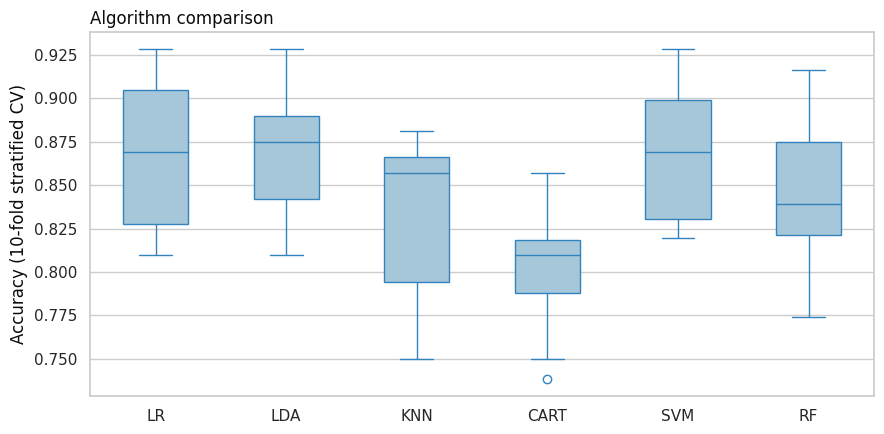

In [29]:
#Algorithms comparison bases on the accuracy distribution over the 10 folds
metrics_df = pd.DataFrame(strat_kfold_metrics)   #one column per model, one row per fold

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=metrics_df, color='#9ecae1', width=0.5, linecolor='#3182bd', ax=ax)

ax.set_ylabel('Accuracy (10-fold stratified CV)', color=BLACK)
ax.set_title('Algorithm comparison', loc='left', color=BLACK)
plt.tight_layout()
plt.show()

**Comments:** Each box shows the distribution of the accuracy over the 10 test folds (the line is the median, the box the interquartile range, the whiskers the range without outliers). The box plot confirms the results of the table above.

- LR, LDA and SVM have the highest medians and their boxes overlap: their differences are negligible compared with the variability between folds.
- Random Forest has a slightly lower mean accuracy (0.845). Its flexibility gives no advantage here, since most features are binary.
- KNN has the largest spreads between folds (std 0.044).
- CART has the lowest median, an outlier fold and since its spread is not larger than the others(std 0.034), it is the worse.

# 8. Final Model


Logistic Regression – classification report
AUC: 0.916
              precision    recall  f1-score   support

         LGG      0.926     0.842     0.882       487
         GBM      0.806     0.906     0.853       352

    accuracy                          0.869       839
   macro avg      0.866     0.874     0.867       839
weighted avg      0.875     0.869     0.870       839



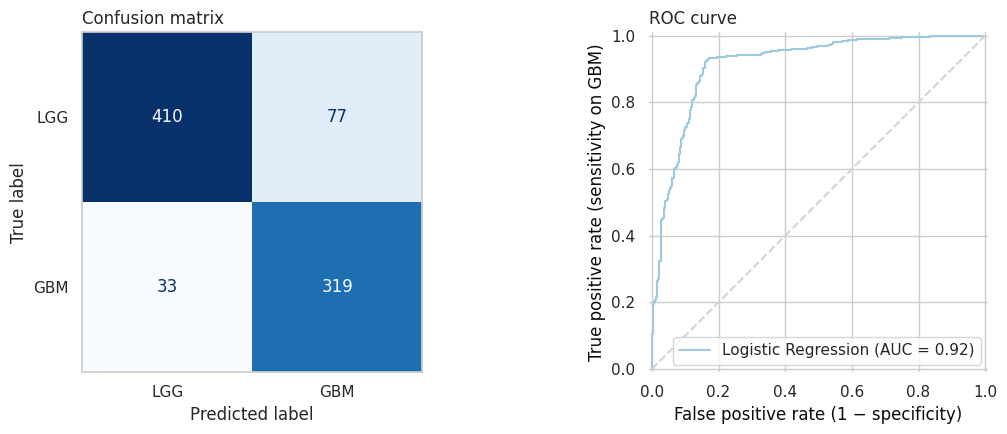

In [30]:
#Final model: Logistic Regression (default C = 1)
final_model = pipelines['LR']

#It returns [P(LGG), P(GBM)] for each patient; [:, 1] keeps the probability of GBM
proba_bin = cross_val_predict(final_model, X, y_bin, cv=strat_kfold, method='predict_proba')[:,1]

#Decision threshold 0.5: GBM (1) if its probability is at least 0.5, otherwise LGG (0)
pred_bin = (proba_bin >= 0.5).astype(int)

print("Logistic Regression – classification report")
print("AUC:", round(roc_auc_score(y_bin, proba_bin), 3))
print(classification_report(y_bin, pred_bin, target_names=['LGG', 'GBM'], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
#Plot for the Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_bin, pred_bin, display_labels=['LGG', 'GBM'], cmap='Blues', colorbar=False, ax=ax[0])
ax[0].set_title('Confusion matrix', loc='left')
ax[0].grid(False)

#Plot for the ROC Curve
RocCurveDisplay.from_predictions(y_bin, proba_bin, name='Logistic Regression', color='#9ecae1', ax=ax[1])
ax[1].plot([0, 1], [0, 1], ls='--', color=SOFT_GREY)
ax[1].set_title('ROC curve', loc='left')
ax[1].set_xlabel('False positive rate (1 − specificity)', color=BLACK)
ax[1].set_ylabel('True positive rate (sensitivity on GBM)', color=BLACK)
for side in ['top', 'right', 'bottom', 'left']:
    ax[1].spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Comments:**
In the confusion matrix:
- TN = LGG correctly classified=410,
- FP = LGG classified as GBM=77,
- FN = GBM classified as LGG=33,
- TP = GBM correctly classified=319.

The model reaches an accuracy of 0.869 and an AUC of 0.92, with a high sensitivity on GBM (recall 0.906) and a higher precision on LGG (0.926). It makes more false positives than false negatives (77 LGG classified as GBM vs 33 GBM classified as LGG), so it tends to over-predict GBM rather than miss it, which is clinically safer: missing a GBM delays treatment of the most aggressive tumour, while labelling an LGG as GBM may lead to overtreatment. This is why the effect of the threshold is examined below.

Since these results use the default decision threshold of 0.5, the next cell shows how they change with other thresholds.

In [31]:
#Effect of the decision threshold on the out-of-fold predictions
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (proba_bin >= t).astype(int)
    rows.append({'Threshold': t,
                 'ACC':  accuracy_score(y_bin, pred_t),
                 'REC (GBM)':  recall_score(y_bin, pred_t),               #sensitivity
                 'SPEC (LGG)': recall_score(y_bin, pred_t, pos_label=0),  #specificity
                 'PRE (GBM)':  precision_score(y_bin, pred_t)})
pd.DataFrame(rows).set_index('Threshold').round(3)

,ACC,REC (GBM),SPEC (LGG),PRE (GBM)
Threshold,,,,
0.3,0.871,0.932,0.828,0.796
0.4,0.874,0.923,0.838,0.804
0.5,0.869,0.906,0.842,0.806
0.6,0.859,0.858,0.860,0.816
0.7,0.826,0.730,0.895,0.834


**Comments:**
The table shows how the errors change with the threshold: lowering it increases the sensitivity on GBM at the cost of more false positives, raising it does the opposite.

The default threshold of 0.5 is kept, since it assigns each patient to the most probable class, choosing the threshold that maximises a metric on these same predictions would give an optimistic estimate.


# 9. Error Analysis

In [32]:
#Error analysis: patients misclassified by the final model
#Creating a pandas DataFrame to analyse the errors by grade, IDH1 status and histological diagnosis
errors = pd.DataFrame({
    'Grade':     y_bin.map({0: 'LGG', 1: 'GBM'}),
    'IDH1':      df_num['IDH1'].map({0: 'wild-type', 1: 'mutant'}),
    'Diagnosis': df_num['Primary_Diagnosis'].astype(str),
    'Correct':   pred_bin == y_bin,
})

#Predictions by group (Grade × IDH1) and by histological diagnosis
print("Predictions by group (Grade × IDH1):")
print(pd.crosstab([errors['Grade'], errors['IDH1']], errors['Correct'], margins=True), '\n')

print("Predictions by histological diagnosis:")
print(pd.crosstab(errors['Diagnosis'], errors['Correct'], margins=True), '\n')

#Error rates: TN = 410, FP = 77, FN = 33, TP = 319
tn, fp, fn, tp = confusion_matrix(y_bin, pred_bin).ravel()
print("FPR = FP / (FP + TN) =", round(fp / (fp + tn), 3))
print("FDR = FP / (FP + TP) =", round(fp / (fp + tp), 3))
print("FNR = FN / (FN + TP) =", round(fn / (fn + tp), 3))


Predictions by group (Grade × IDH1):
Correct          False  True  All
Grade IDH1                       
GBM   mutant        23     0   23
      wild-type     10   319  329
LGG   mutant         0   381  381
      wild-type     77    29  106
All                110   729  839 

Predictions by histological diagnosis:
Correct                        False  True  All
Diagnosis                                      
Astrocytoma, NOS                   2    54   56
Astrocytoma, anaplastic           44    83  127
Glioblastoma                      33   319  352
Mixed glioma                      16   111  127
Oligodendroglioma, NOS             7    97  104
Oligodendroglioma, anaplastic      8    65   73
All                              110   729  839 

FPR = FP / (FP + TN) = 0.158
FDR = FP / (FP + TP) = 0.194
FNR = FN / (FN + TP) = 0.094


**Comments:**
- The model makes 110 errors out of 839 predictions, concentrated where IDH1 contradicts the histological grade: **IDH1-mutant GBM 0 of 23 correct and IDH1-wildtype LGG only 29 of 106**, while IDH1-mutant LGG and IDH1-wildtype GBM are almost perfectly classified. The model therefore essentially reproduces the IDH1 rule.
- The model has a **false positive rate of 0.158** (77 of 487 LGG classified as GBM) and a **false discovery rate of 0.194** (77 of the 396 patients predicted as GBM are actually LGG). The **false negative rate is 0.094** (33 of 352 GBM missed). All the false positives are IDH1-wildtype LGG, while most of the false negatives (23 of 33) are IDH1-mutant GBM.
- By histological diagnosis, **anaplastic astrocytoma is the most misclassified subtype** (44 of 127), consistent with the EDA heatmap.
- Biological interpretation: these cases are consistent with the disagreement between the TCGA histological labels and the WHO 2021 classification. An IDH-mutant “GBM” would today be classified as astrocytoma, IDH-mutant, grade 4, and some IDH-wildtype “LGG”, often anaplastic astrocytomas, could be molecular glioblastomas; the dataset does not contain the markers needed to verify this. A large part of the errors therefore probably reflects the labels rather than a failure of the model.

# 10. Feature subsets comparison: contribution of IDH1

The feature selection analysis (section 5) suggested that IDH1 is the key feature, but it was exploratory and fitted on the whole dataset. To test this hypothesis, the same model LR and the same 10-fold stratified cross-validation are applied to different subsets of features:
- IDH1 alone
- IDH1 with Age
- All without IDH1
- Only genes
- Genes with Age
- Genes without IDH1
- All features


Comparing the results shows how much each group of features contributes to the prediction.

In [33]:
#Creating feature subset of columns for the comparison:
feature_sets = {
    'IDH1 only':           ['IDH1'],
    'IDH1 + Age':          ['IDH1', 'Age_at_diagnosis'],
    'All without IDH1':    [c for c in feature_cols if c != 'IDH1'],
    'Genes only':          gene_cols,
    'Genes + Age':         gene_cols + ['Age_at_diagnosis'],
    'Genes without IDH1':  [g for g in gene_cols if g != 'IDH1'],
    'All features':        feature_cols,
}


rows = []
for set_name, columns in feature_sets.items():
    #Preprocessing restricted to the columns of the set (same transformations as the main preprocessor)
    prep = ColumnTransformer([
        ('age',  StandardScaler(), [c for c in columns if c in clinical_num]),
        ('race', OneHotEncoder(categories=[Race_cat], drop='first', sparse_output=False),
                 [c for c in columns if c in clinical_cat]),
        ('bin',  'passthrough', [c for c in columns if c in binary_cols]),
    ])
    #Applying the Pipeline
    pipe = Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000, random_state=0))])

    #Model
    res = cross_validate(pipe, X[columns], y_bin, cv=strat_kfold, scoring=metrics)
    rows.append({'Feature set': set_name,
                 'N. features': len(columns),
                 'ACC':         res['test_ACC'].mean(),
                 'AUC':         res['test_AUC'].mean(),
                 'REC':         res['test_REC'].mean(),
                 'SPEC':        res['test_SPEC'].mean(),
                 'F1':          res['test_F1'].mean()
  })

#Each metric is computed on each of the 10 test folds and then averaged
res_featsets = pd.DataFrame(rows)
res_featsets.round(3)

,Feature set,N. features,ACC,AUC,REC,SPEC,F1
0,IDH1 only,1,0.846,0.859,0.935,0.782,0.837
1,IDH1 + Age,2,0.855,0.899,0.909,0.815,0.841
2,All without IDH1,22,0.814,0.889,0.781,0.838,0.777
3,Genes only,20,0.875,0.910,0.929,0.836,0.862
4,Genes + Age,21,0.870,0.920,0.909,0.842,0.855
5,Genes without IDH1,19,0.766,0.854,0.665,0.840,0.704
6,All features,23,0.869,0.919,0.906,0.842,0.853


**Comments:**
IDH1 alone reaches an accuracy of 0.846, reproducing the clinical rule “IDH1-mutant -> LGG, IDH1-wildtype -> GBM”: it detects almost all glioblastomas (REC 0.935) but misclassifies the IDH1-wildtype LGG (SPEC 0.782).
Adding age improves the ranking (AUC 0.859 vs 0.899) and the specificity (0.815), because IDH1-wildtype LGG are younger than GBM, at the cost of some sensitivity (0.909).
Removing IDH1 causes the largest drop (ACC 0.814 vs 0.869), almost entirely in the sensitivity on GBM (0.781 vs 0.906), while the specificity remains essentially the same (0.838 vs 0.842).
The 20 genes alone perform as well as the full model, and the other features add little in accuracy.
Age adds only a marginal gain in AUC (0.910 vs 0.920) and no gain in accuracy, while gender and race add nothing. The differences among Genes only, Genes + Age and All features are well below the fold-to-fold variability (std about 0.04), therefore these models are equivalent in accuracy.

All 23 features are kept in the final model because they are all available in practice and the full model has the highest AUC, but the 20 genes alone would be a simpler alternative with equivalent performance.

Overall, IDH1 confirms what the feature selection analysis suggested: it is the single most important feature and it is what allows the model to recognise glioblastomas.

# 11. Hyperparameter tuning
Hyperparameter tuning searches for the values that give the best performance: in a **Grid Search**, every combination of a predefined set of values is evaluated with cross-validation, and the best one is selected.
The main **hyperparameter of Logistic Regression is C**, the inverse of the regularisation strength: a small C means a stronger regularisation and a simpler model. C has been tuned together with the solver (the optimisation algorithm), to check that the choice of the algorithm does not change the model. I leave the penalty (L2) and the class weights at their defaults.

In [34]:
#Setting key hyperparameters of Logistic Regression
solvers  = ['newton-cg', 'lbfgs', 'liblinear']
penalty  = ['l2']
c_values = [100, 10, 1.0, 0.1, 0.01, 0.001]

# 'clf__' prefix: the parameters belong to the 'clf' step of the pipeline
grid = dict(clf__solver=solvers, clf__penalty=penalty, clf__C=c_values)

#Performing GridSearch over the key hyperparameters
grid_search = GridSearchCV(estimator=pipelines['LR'], param_grid=grid, n_jobs=-1, cv=strat_kfold, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(X, y_bin)
print("Best: %.3f using %s" % (grid_result.best_score_, grid_result.best_params_))

#Mean accuracy for each value of C (rows) and solver (columns)
res_grid = pd.DataFrame(grid_result.cv_results_)
res_grid.pivot(index='param_clf__C', columns='param_clf__solver', values='mean_test_score').round(3)

Best: 0.874 using {'clf__C': 100, 'clf__penalty': 'l2', 'clf__solver': 'newton-cg'}


param_clf__solver,lbfgs,liblinear,newton-cg
param_clf__C,,,
0.001,0.637,0.782,0.637
0.010,0.838,0.838,0.838
0.100,0.868,0.865,0.868
1.000,0.869,0.869,0.869
10.000,0.871,0.871,0.871
100.000,0.872,0.874,0.874


**Comments.**
- The **best configuration** (C = 100, accuracy 0.874) improves on the default C = 1 (0.869) by only 0.005, so the default C = 1 is kept.
- **C:** the accuracy is on a plateau (0.865–0.874)between 0.1 and 100 and drops only with strong regularisation (C ≤ 0.01: underfitting).
- **Solver:** for C ≥ 0.01 the three solvers give practically the same accuracy (differences <= 0.003), so the solver does not change the model. The only difference, at C = 0.001, comes from `liblinear` which also regularising the intercept, in a range of strong underfitting.

In [35]:
#Checking for overfitting by comparing the train and test accuracy of the Logistic Regression over the 10 folds
res_lr = cross_validate(pipelines['LR'], X, y_bin, cv=strat_kfold, scoring='accuracy', return_train_score=True)
print(f"Train accuracy: {res_lr['train_score'].mean():.3f}")
print(f"Test accuracy:  {res_lr['test_score'].mean():.3f}")

Train accuracy: 0.876
Test accuracy:  0.869


Training and test accuracy are very close: **0.876 vs 0.869**, so the model doesn't overfit: it generalises to unseen folds as well as it fits the training data whereas overfitting would show a training accuracy much higher than the test accuracy.
The remaining errors therefore suggest the limits of the features and labels rather than of the model.



# 12. Conclusions and Limitations

**Research question:** *Can tumour grade (LGGvs GBM) be predicted from the clinical and mutational profile, and in particular from IDH1?*

- **Yes.** Logistic Regression on all 23 features reaches **accuracy 0.869 and AUC 0.919** in 10-fold stratified cross-validation,with a sensitivity on GBM of 0.906 and a specificity of 0.842.

- **IDH1 is the key feature**: on its own it reaches 0.846, exactly as the clinical rule *"IDH1-mutant -> LGG, IDH1-wildtype -> GBM"*; age improves it mainly by identifying IDH1-wildtype LGG (AUC 0.859 vs 0.899). Without IDH1 the sensitivity on GBM falls and the other genes add about 3 points of accuracy to IDH1 alone, while gender and race add no further improvement in accuracy.

- **Model choice.** LR, LDA and SVM perform equivalently within the fold variability (accuracy 0.869–0.871). Logistic Regression was chosen for its lowest log loss, its highest AUC. Tuning C and the solver did not give a meaningful improvement, so the default configuration was kept, and the similar train and test accuracy shows no sign of overfitting.

- **Errors.** The model misclassifies 110 of 839 patients, almost all of them where IDH1 contradicts the histological grade: 23 IDH1-mutant GBM and 77 IDH1-wildtype LGG, plus 10 IDH1-wildtype GBM. These cases are consistent with the disagreement between the TCGA histological labels and the WHO 2021 molecular classification.



## 12.1 Limitations
- **No independent test set.** Model comparison, threshold analysis and hyperparameter tuning were all evaluated on the same 10 folds, so the reported performance may be slightly optimistic.
- **Single cohort.** All patients come from TCGA and the cohort is strongly dominated by white patients, so the results may not generalise to other populations or centres.
- **Labels and features.** The target is the original histological grade. The dataset contains only mutations of 20 genes, age, gender and race, without the markers used in the WHO 2021 classification for molecular glioblastoma, so some labels disagrees with the molecular classification.
